<a href="https://colab.research.google.com/github/Gaborobles/Programacion-para-IA/blob/main/pia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Proyecto final**

José Gael alejo López 2192941 Carlos Adrian Rivera Salinas 2208957 Haldir Alejandro Castillo Bautista 2173180 José Gael alejo López 219294 Gabriel Villagómez Robles 2208997 Arturo Cortés Alanís 2208600.

## **1. Carga del Conjunto de Datos Público**


Se importan las librerias y el dataset con el uso de pandas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import sklearn.datasets

In [ ]:
columns = [ 'ID', 'Diagnosis', 'mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness',
    'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension',
    'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error',
    'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error',
    'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness',
    'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
df = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data", header=None, names=columns)
print("Primeras filas del dataset original:")
print(df.head())

Primeras filas del dataset original:
         ID Diagnosis  mean radius  mean texture  mean perimeter  mean area  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   mean smoothness  mean compactness  mean concavity  mean concave points  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  worst radius  wor

## **2. Análisis Exploratorio y Visualización**

Se utiliza df.describe para tener un analisis estadistico de las variables, df.info y df.isnull para comprobar que no haya valores nulos. Al final se usa matplotlib para generar un diagrama de dispersión que relaciona la media del radio de los nucleos con la media de la textura, pandas nos ayuda a separar las personas con tumores benignos de los malignos.

In [ ]:

df.describe()

,ID,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [ ]:
df.info()
print("**********************************")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       569 non-null    int64  
 1   Diagnosis                569 non-null    object 
 2   mean radius              569 non-null    float64
 3   mean texture             569 non-null    float64
 4   mean perimeter           569 non-null    float64
 5   mean area                569 non-null    float64
 6   mean smoothness          569 non-null    float64
 7   mean compactness         569 non-null    float64
 8   mean concavity           569 non-null    float64
 9   mean concave points      569 non-null    float64
 10  mean symmetry            569 non-null    float64
 11  mean fractal dimension   569 non-null    float64
 12  radius error             569 non-null    float64
 13  texture error            569 non-null    float64
 14  perimeter error          5

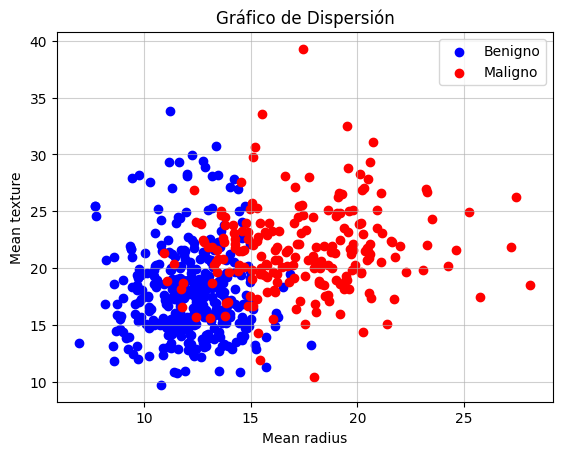

In [ ]:
tumorbien = df[df['Diagnosis'] == 'B']
tumormal = df[df['Diagnosis'] == 'M']
plt.scatter(tumorbien['mean radius'], tumorbien['mean texture'], color='blue', label="Benigno")
plt.scatter(tumormal['mean radius'], tumormal['mean texture'], color='red', label="Maligno")
plt.title("Gráfico de Dispersión")
plt.xlabel("Mean radius")
plt.ylabel("Mean texture")
plt.legend()
plt.grid(True, alpha=0.6)
plt.show()

## **3. Limpieza y Preprocesamiento de Datos**

 Con la ayuda de pandas verificamos que no hay ningun dato nulo ni valores faltantes en el dataset. Para terminar se usó Numpy y pandas para filtrar la columna de mean area y que esta solo conserve los valores dentro del rango intercuartilico.

In [ ]:
df.isnull().sum()

,0
ID,0
Diagnosis,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0


In [ ]:
q1 = np.nanpercentile(df['mean area'], 25)
q3 = np.nanpercentile(df['mean area'], 75)
print(q1, q3)
iqr = q3 - q1
inflim = q1 - 1.5 * iqr
suplim = q3 + 1.5 * iqr
df = df[(df['mean area'] >= inflim) & (df['mean area'] <= suplim)]
print(len(df))

420.3 782.7
544


## **4. Entrenamiento y Evaluación del Árbol de Decisión**

Se usó Pandas, Scikit-learn y matplotlib para entrenar, testear y generar un arbol de decisión. Primero se asignaron a 'X' las columnas de características independientes (excluyendo las columnas de ID y Diagnosis) y a 'y' la columna de 'Diagnosis' que es la que guarda el valor de si el tumor es benigno o maligno. Se dividen los datos del dataset y se asigna solo el 25% de los datos en el dataset (test_size=0.25) para la prueba y el 75% al entrenamiento. Se entrena el arbol de decisión y se evalua el desempeño del modelo usando: accuracy = accuracy_score(y_test, y_pred). Al final se usa matplotlib para visualizar el arból de decisión.

In [ ]:
X = df.drop(columns=['ID', 'Diagnosis'])
y = df['Diagnosis'].map({'M': 1, 'B': 0})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(408, 30) (136, 30)


In [ ]:
model = DecisionTreeClassifier(random_state=42, max_depth=3)
model.fit(X_train, y_train)
train_accuracy = model.score(X_train, y_train)
print(train_accuracy)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print(classification_report(y_test, y_pred))


0.9779411764705882
Accuracy: 0.9191176470588235
              precision    recall  f1-score   support

           0       0.91      0.98      0.94        89
           1       0.95      0.81      0.87        47

    accuracy                           0.92       136
   macro avg       0.93      0.89      0.91       136
weighted avg       0.92      0.92      0.92       136



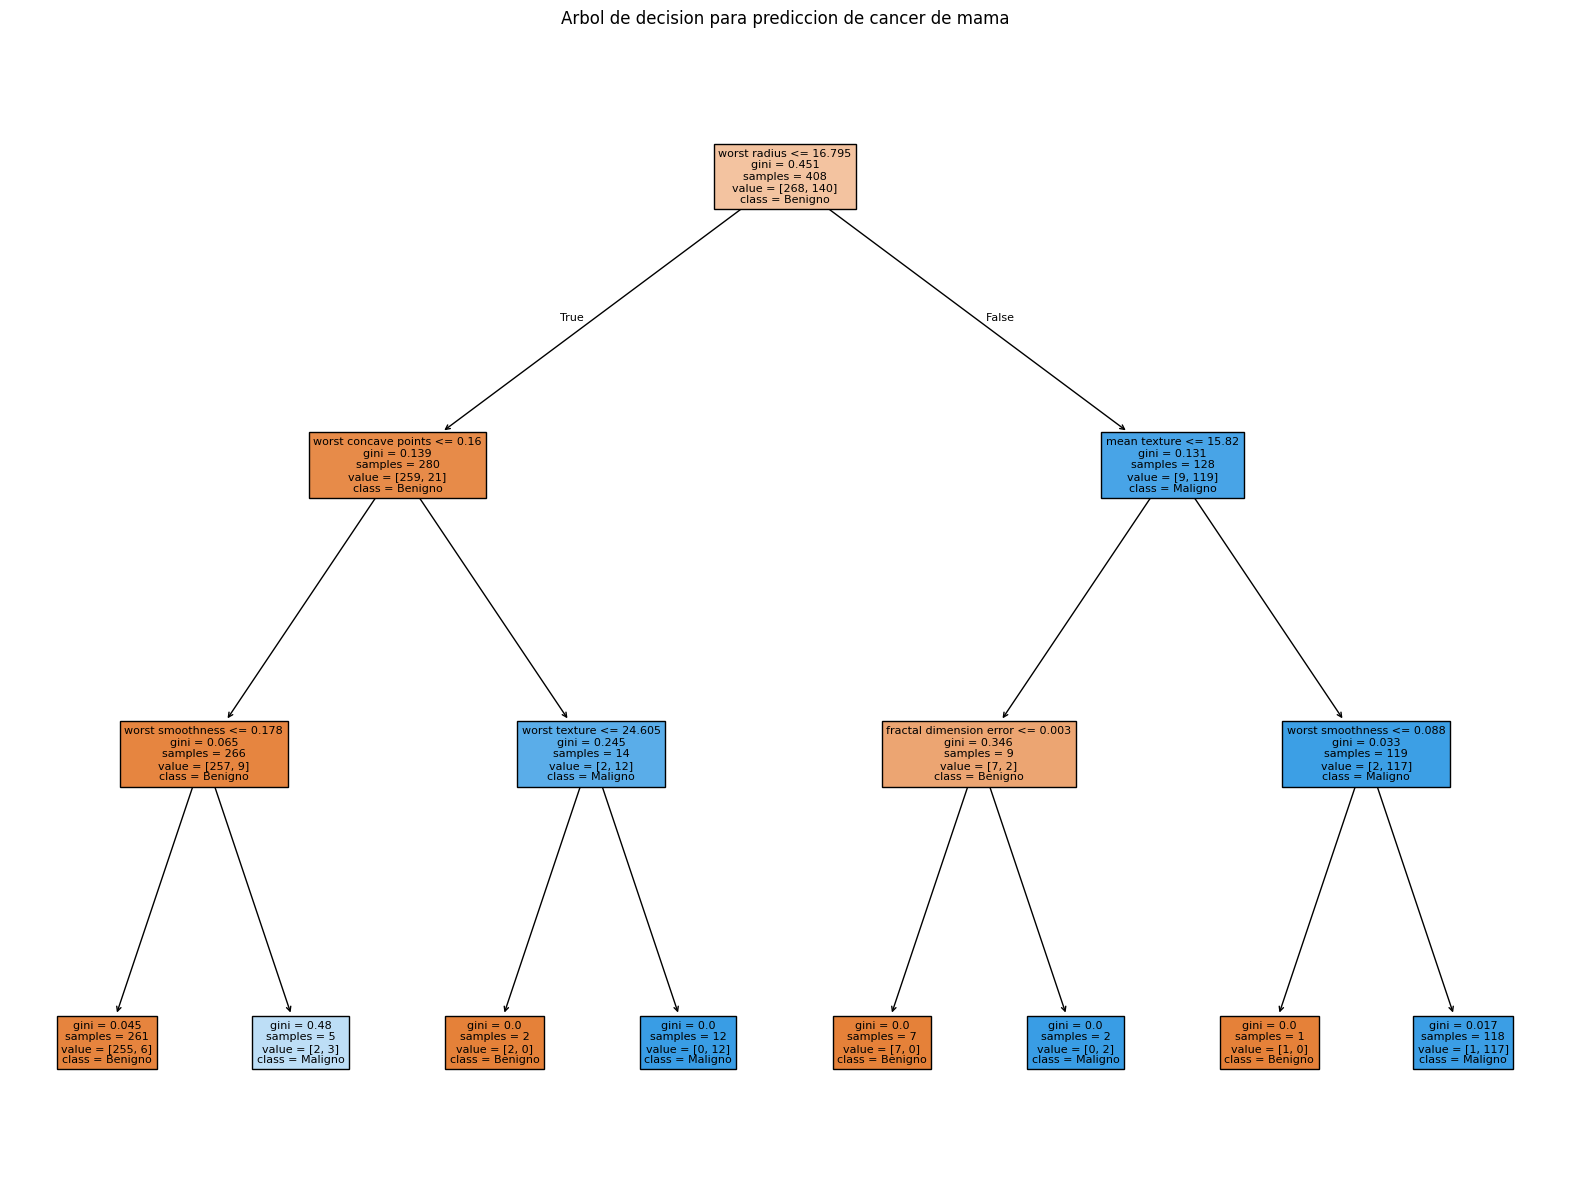

In [ ]:
plt.figure(figsize=(20, 15))
plot_tree(model, filled=True, feature_names=X.columns, class_names=['Benigno', 'Maligno'])
plt.title("Arbol de decision para prediccion de cancer de mama")
plt.savefig("decision_tree.png", dpi=300)
plt.show()